# Pertemuan 10 - Dasar-dasar Deteksi Objek

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Adidtiasmara/PCVK26_16_Firman/blob/main/week10_16.ipynb)

**Nama : Muhammad Firman Aditiasmara** · **Absen : 16**

Praktikum ini mengimplementasikan metode-metode dasar deteksi objek:

1. Template Matching
2. Edge Detection
3. Corner Detection
4. Grid Detection
5. Contour Detection
6. Feature Matching & Face Detection

In [1]:
import os
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

PATH   = r'd:/Data Tugas/SEM 5/PCVK/asset'            # folder asset modul
IMG    = os.path.join(PATH, 'Images Object Detection')  # citra praktikum deteksi objek
FD     = os.path.join(PATH, 'facedet')                 # citra face detection
HAAR   = os.path.join(PATH, 'haarcascades')            # pretrained features XML
OUTPUT = 'output'
os.makedirs(OUTPUT, exist_ok=True)

print('OpenCV :', cv.__version__)
print('IMG    :', IMG)
print('FD     :', FD)
print('HAAR   :', HAAR)

OpenCV : 4.12.0
IMG    : d:/Data Tugas/SEM 5/PCVK/asset\Images Object Detection
FD     : d:/Data Tugas/SEM 5/PCVK/asset\facedet
HAAR   : d:/Data Tugas/SEM 5/PCVK/asset\haarcascades


## D1. Praktikum Deteksi Obyek Dasar

### 1. Template Matching (6 Metode)

Ukuran citra sumber : (829, 1024, 3)
Ukuran template     : (449, 356)


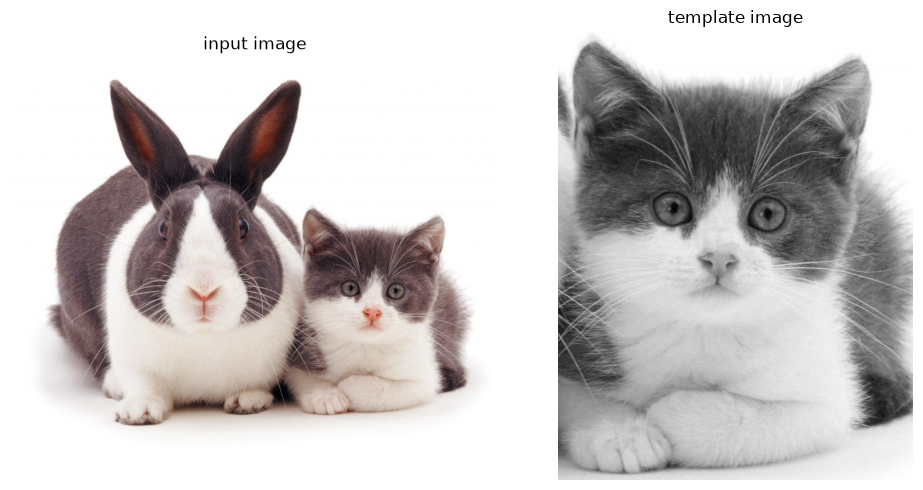

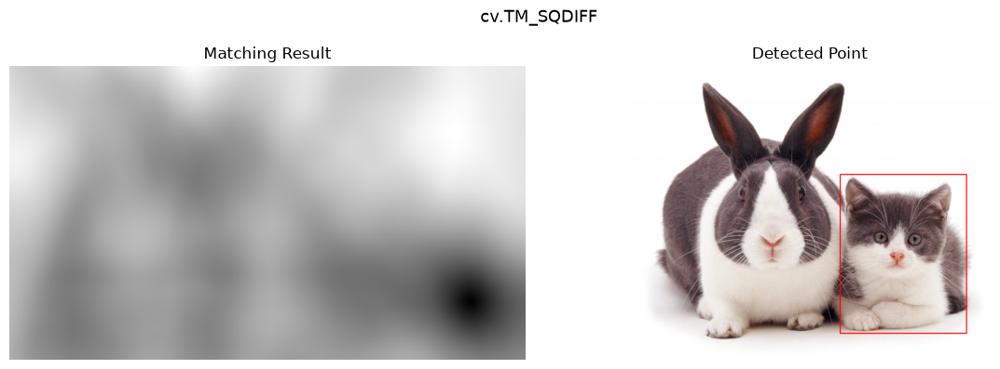

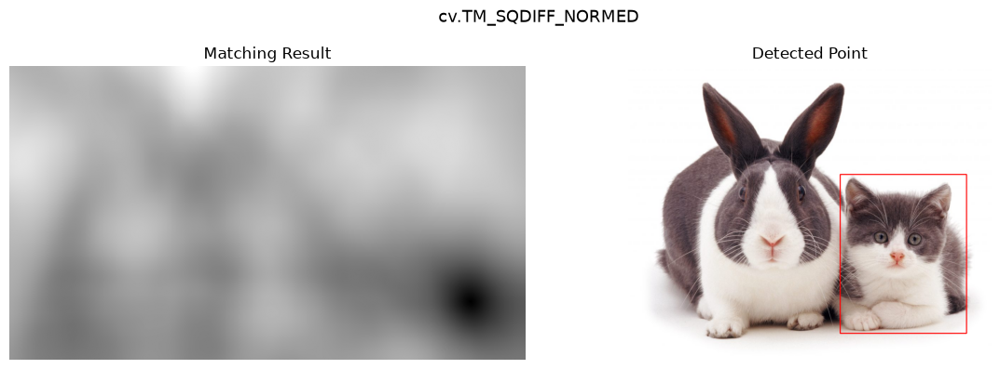

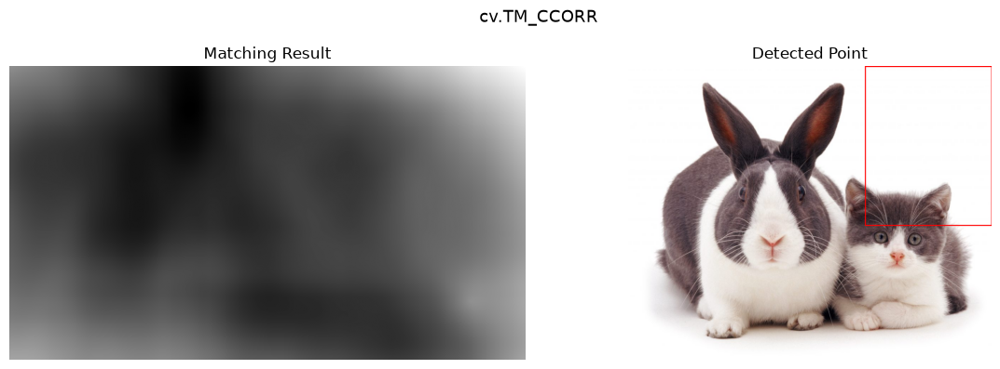

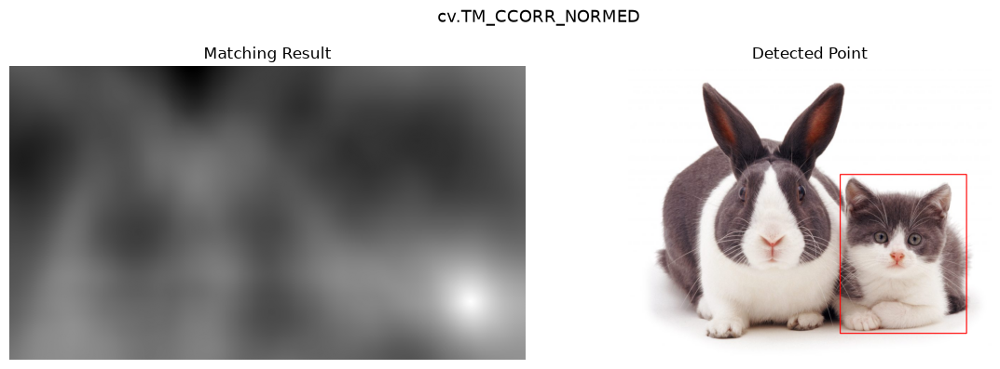

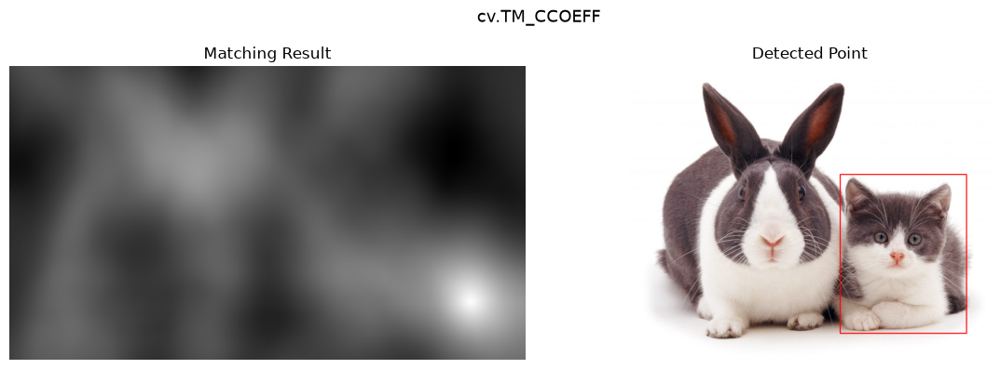

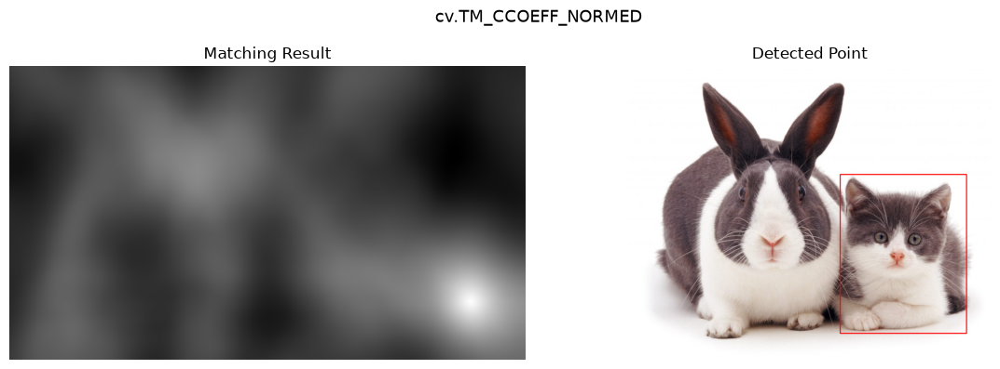

In [2]:
main_img = cv.imread(os.path.join(IMG, 'cats_and_bunnies.jpg'))
img_gray = cv.cvtColor(main_img, cv.COLOR_BGR2GRAY)
template = cv.imread(os.path.join(IMG, 'cat2_templatejpg.jpg'), 0)
w, h = template.shape[::-1]

print('Ukuran citra sumber :', main_img.shape)
print('Ukuran template     :', template.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv.cvtColor(main_img, cv.COLOR_BGR2RGB)); ax[0].set_title('input image');    ax[0].axis('off')
ax[1].imshow(template, cmap='gray');                    ax[1].set_title('template image'); ax[1].axis('off')
plt.tight_layout(); plt.show()

methods = ['TM_SQDIFF', 'TM_SQDIFF_NORMED', 'TM_CCORR',
           'TM_CCORR_NORMED', 'TM_CCOEFF', 'TM_CCOEFF_NORMED']

for meth in methods:
    method = getattr(cv, meth)
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    # TM_SQDIFF & TM_SQDIFF_NORMED: kecocokan terbaik berada pada nilai terkecil
    if meth in ('TM_SQDIFF', 'TM_SQDIFF_NORMED'):
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    hasil = main_img.copy()
    cv.rectangle(hasil, top_left, bottom_right, (0, 0, 255), 2)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f'cv.{meth}', fontsize=13)
    ax[0].imshow(res, cmap='gray');                      ax[0].set_title('Matching Result'); ax[0].axis('off')
    ax[1].imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB));  ax[1].set_title('Detected Point');  ax[1].axis('off')
    plt.tight_layout(); plt.show()
    cv.imwrite(os.path.join(OUTPUT, f'soal2_{meth}.jpg'), hasil)

### 2. Template Matching tanpa Library OpenCV (Multiple Object)

Ukuran citra sumber : (586, 596, 3)
Ukuran template     : (73, 88)


Jumlah objek terdeteksi : 6


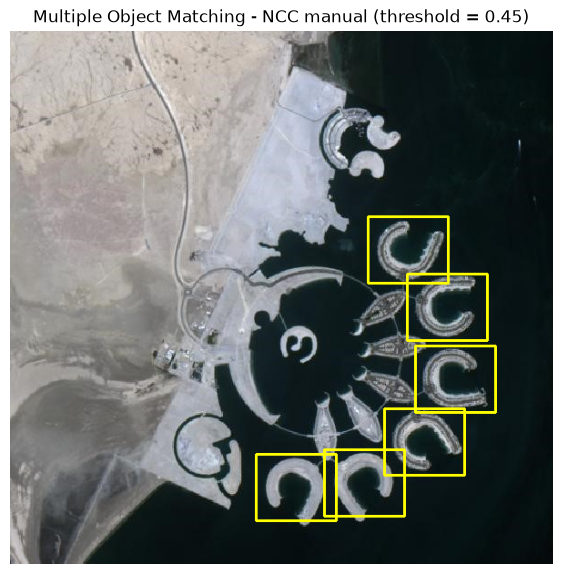

True

In [3]:
img_rgb  = cv.imread(os.path.join(IMG, 'bahrain.jpg'))
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY).astype(np.float32)
template = cv.imread(os.path.join(IMG, 'bahrain-template.jpg'), 0).astype(np.float32)
th, tw = template.shape
print('Ukuran citra sumber :', img_rgb.shape)
print('Ukuran template     :', template.shape)

# ---------- template matching manual (NCC) tanpa cv.matchTemplate ----------
T = template - template.mean()
t_norm = np.sqrt((T ** 2).sum())

windows = np.lib.stride_tricks.sliding_window_view(img_gray, (th, tw))
ncc = np.empty(windows.shape[:2], dtype=np.float32)
for i in range(windows.shape[0]):                    # diproses per baris agar hemat memori
    baris = np.ascontiguousarray(windows[i]).reshape(windows.shape[1], -1)
    baris -= baris.mean(axis=1, keepdims=True)
    pembilang = baris @ T.ravel()
    penyebut  = np.sqrt((baris ** 2).sum(axis=1)) * t_norm
    ncc[i] = pembilang / penyebut

# ---------- ambil semua posisi bernilai tinggi, lalu NMS ----------
threshold = 0.45
ys, xs = np.where(ncc >= threshold)
kandidat = sorted(zip(map(float, ncc[ys, xs]), xs.tolist(), ys.tolist()), reverse=True)

kotak = []
for skor, x, y in kandidat:
    if all(abs(x - kx) > tw * 0.5 or abs(y - ky) > th * 0.5 for kx, ky in kotak):
        kotak.append((x, y))                          # non-maximum suppression sederhana
print('Jumlah objek terdeteksi :', len(kotak))

hasil = img_rgb.copy()
for x, y in kotak:
    cv.rectangle(hasil, (x, y), (x + tw, y + th), (0, 255, 255), 2)

plt.figure(figsize=(7, 7))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title(f'Multiple Object Matching - NCC manual (threshold = {threshold})')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal3_bahrain_multiple.jpg'), hasil)

### 3. Edge Detection: Sobel, Canny, Laplacian

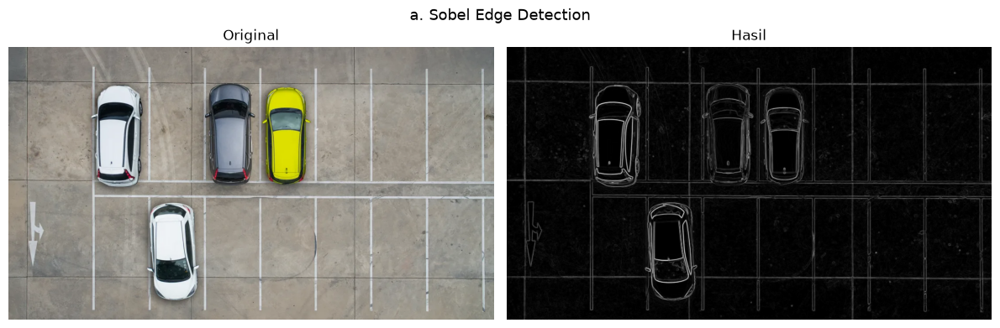

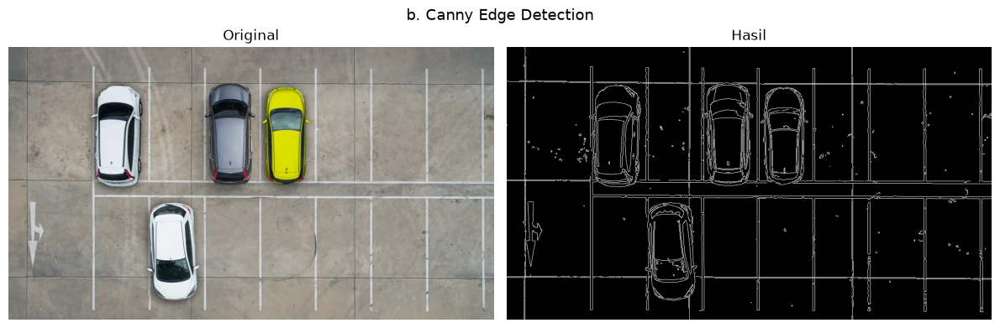

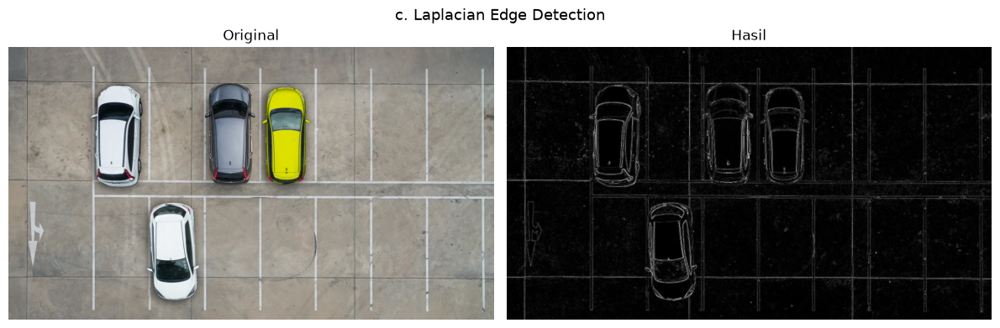

In [4]:
img  = cv.imread(os.path.join(IMG, 'car-park.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(gray, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray, cv.CV_64F, 0, 1, ksize=3)
sobel  = np.sqrt(sobelx ** 2 + sobely ** 2)
sobel  = np.uint8(sobel / sobel.max() * 255)

# b. Canny Edge Detection
canny = cv.Canny(gray, 100, 200)

# c. Laplacian Edge Detection
lap = cv.Laplacian(gray, cv.CV_64F)
lap = np.uint8(np.absolute(lap))

judul = ['a. Sobel Edge Detection', 'b. Canny Edge Detection', 'c. Laplacian Edge Detection']
hasil_edge = [sobel, canny, lap]
for j, (t, r) in enumerate(zip(judul, hasil_edge)):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(t, fontsize=13)
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); ax[0].set_title('Original'); ax[0].axis('off')
    ax[1].imshow(r, cmap='gray');                     ax[1].set_title('Hasil');    ax[1].axis('off')
    plt.tight_layout(); plt.show()
    cv.imwrite(os.path.join(OUTPUT, f'soal4_{chr(97 + j)}.jpg'), r)

### 4. Corner Detection: Harris & Shi-Tomasi

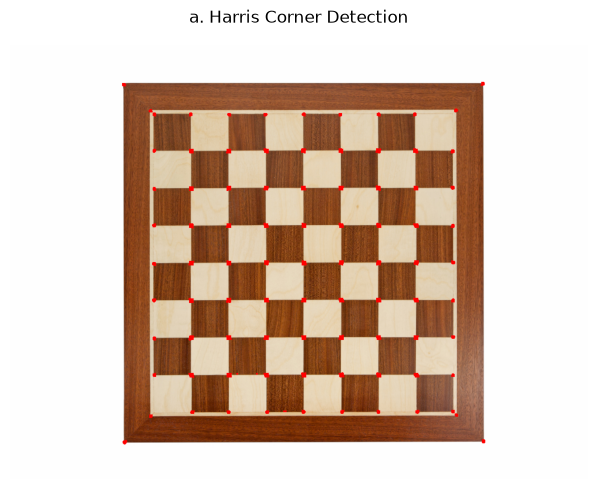

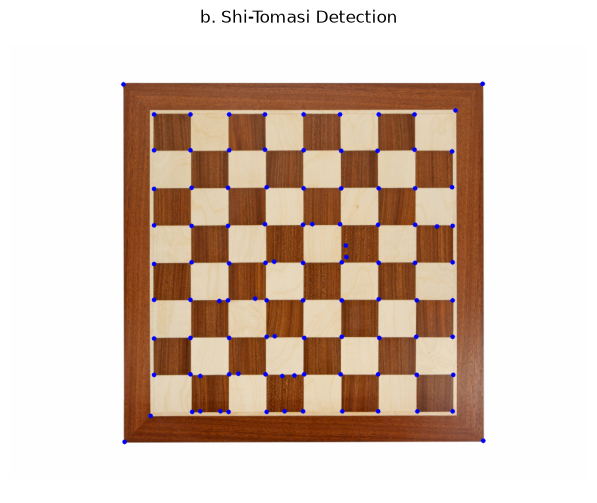

True

In [5]:
img  = cv.imread(os.path.join(IMG, 'chess-board.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
harris_in = img.copy()
dst = cv.cornerHarris(np.float32(gray), 4, 5, 0.04)
dst = cv.dilate(dst, None)                      # memperjelas titik sudut
harris_in[dst > 0.01 * dst.max()] = [0, 0, 255]  # titik sudut berwarna merah

# b. Shi-Tomasi Detection
shi_in = img.copy()
corners = cv.goodFeaturesToTrack(gray, 100, 0.01, 10)
corners = np.intp(corners)
for i in corners:
    x, y = i.ravel()
    cv.circle(shi_in, (x, y), 4, (255, 0, 0), -1)  # titik sudut berwarna biru

for t, r in [('a. Harris Corner Detection', harris_in),
             ('b. Shi-Tomasi Detection', shi_in)]:
    plt.figure(figsize=(8, 6))
    plt.imshow(cv.cvtColor(r, cv.COLOR_BGR2RGB))
    plt.title(t); plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal5a_harris.jpg'), harris_in)
cv.imwrite(os.path.join(OUTPUT, 'soal5b_shitomasi.jpg'), shi_in)

### 5. Grid Detection — Hough Transform

Jumlah garis terdeteksi  : 74
Setelah penggabungan     : 40


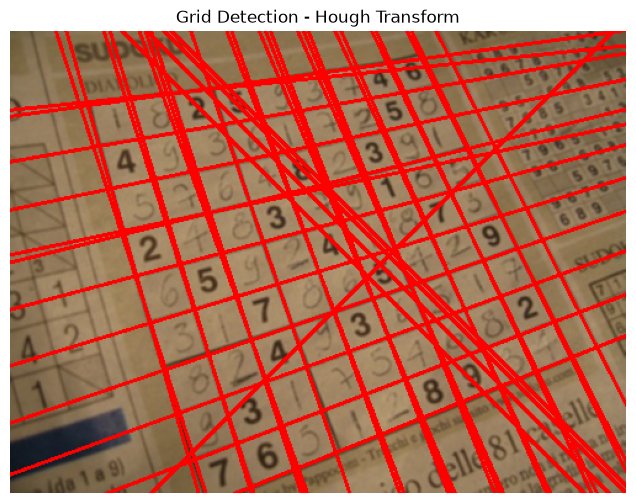

True

In [6]:
img  = cv.imread(os.path.join(IMG, 'sudoku.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. Canny Edge Detection
edges = cv.Canny(gray, 90, 150, apertureSize=3)
# 2. Dilasi gambar tepi
kernel = np.ones((3, 3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
# 3. Erosi
edges = cv.erode(edges, kernel, iterations=1)

# 4. HoughLines
lines = cv.HoughLines(edges, 1, np.pi / 180, 220)
lines = lines[:, 0, :]                       # (N, 1, 2) -> (N, 2): rho, theta
print('Jumlah garis terdeteksi  :', len(lines))

# 5. Gabungkan garis yang mirip (similar lines)
buang = np.zeros(len(lines), dtype=bool)
for i in range(len(lines)):
    if buang[i]:
        continue
    rho, theta = lines[i]
    beda_rho   = np.abs(lines[i + 1:, 0] - rho) < 5
    beda_theta = np.minimum(np.abs(lines[i + 1:, 1] - theta),
                            np.pi - np.abs(lines[i + 1:, 1] - theta)) < 0.05
    buang[i + 1:] |= beda_rho & beda_theta
garis = lines[~buang]
print('Setelah penggabungan     :', len(garis))

hasil = img.copy()
for rho, theta in garis:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
    p2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
    cv.line(hasil, p1, p2, (0, 0, 255), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title('Grid Detection - Hough Transform')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal6_sudoku_hough.jpg'), hasil)

### 6. Contour Detection — findContours()

Jumlah kontur ditemukan : 275


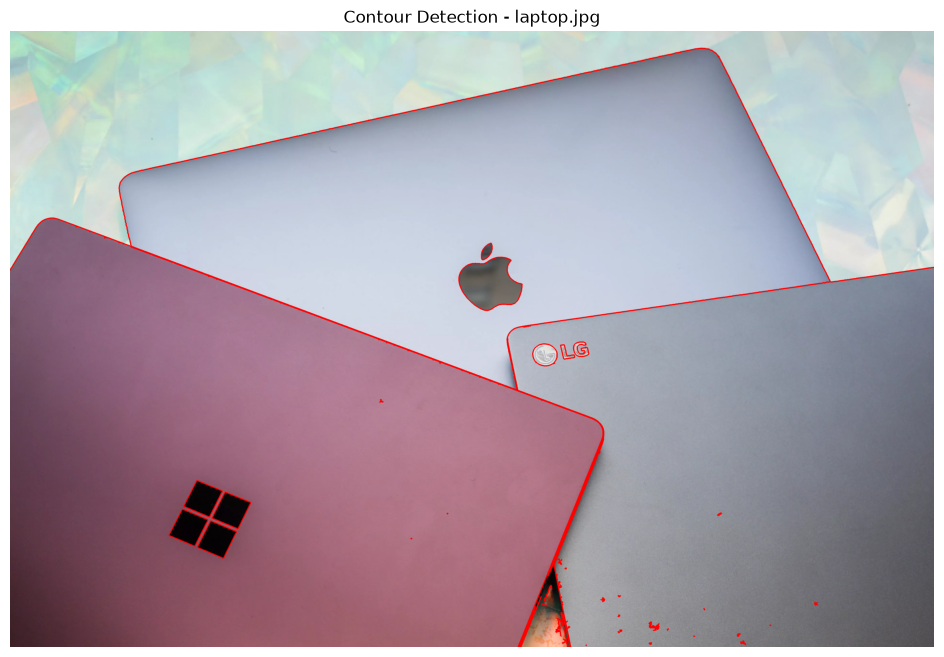

True

In [7]:
img  = cv.imread(os.path.join(IMG, 'laptop.jpg'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 1. citra biner dengan Canny
edged = cv.Canny(gray, 30, 150)

# 2. menemukan kontur
contours, hierarchy = cv.findContours(edged, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
print('Jumlah kontur ditemukan :', len(contours))

# 3. menggambarkan kontur
hasil = img.copy()
cv.drawContours(hasil, contours, -1, (0, 0, 255), 3)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
plt.title('Contour Detection - laptop.jpg')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal7_laptop_contour.jpg'), hasil)

## D2. Praktikum Feature Matching dan Face Detection

### 7. Face Detection (Haar Cascade - Viola-Jones)

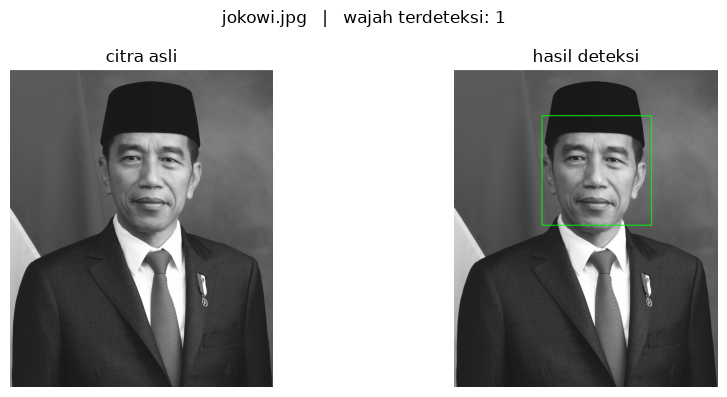

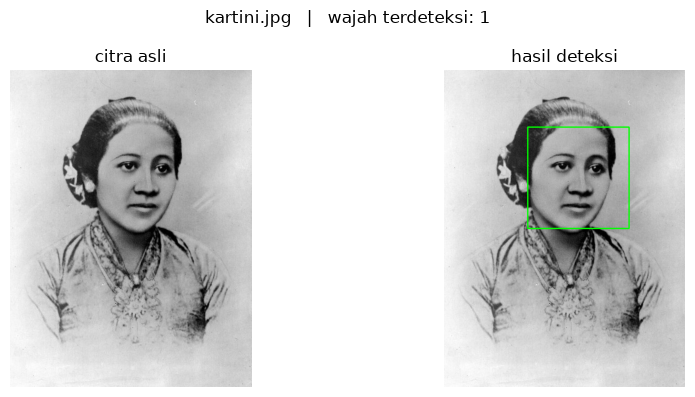

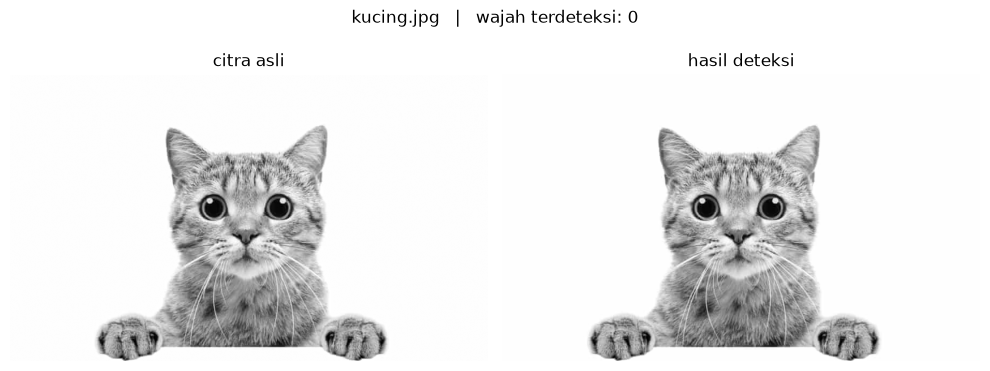

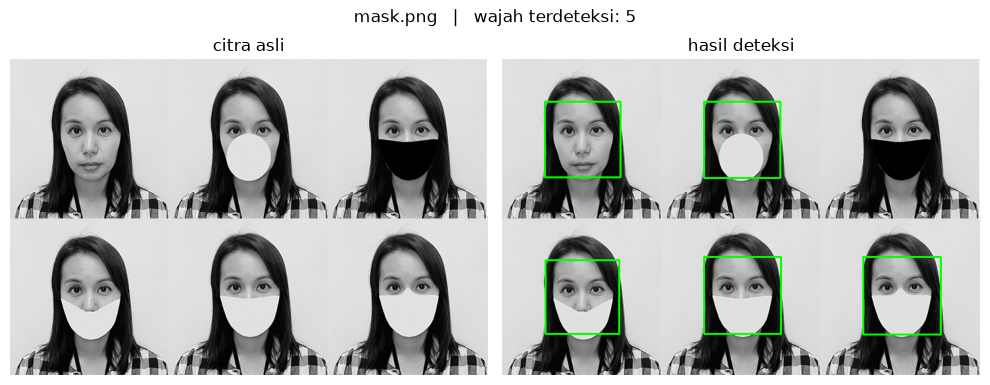

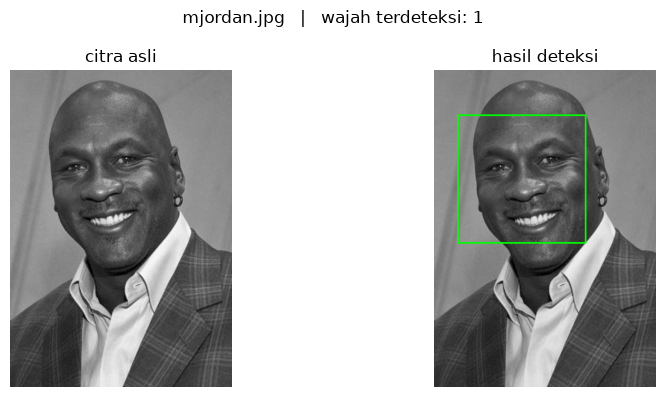

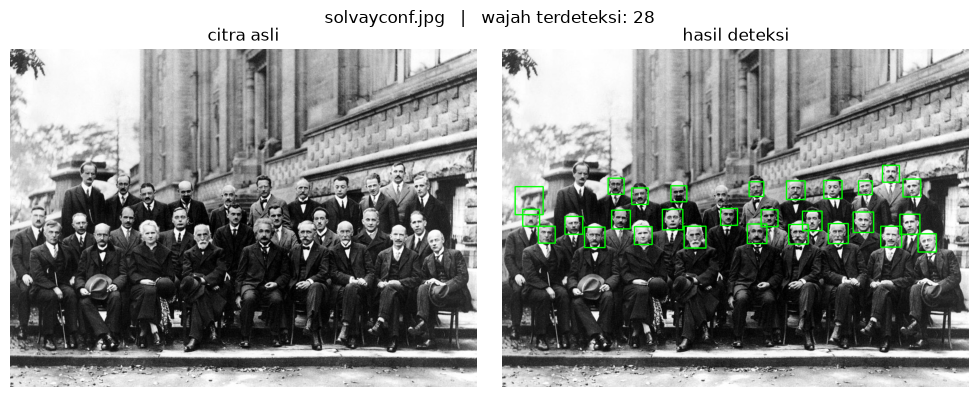

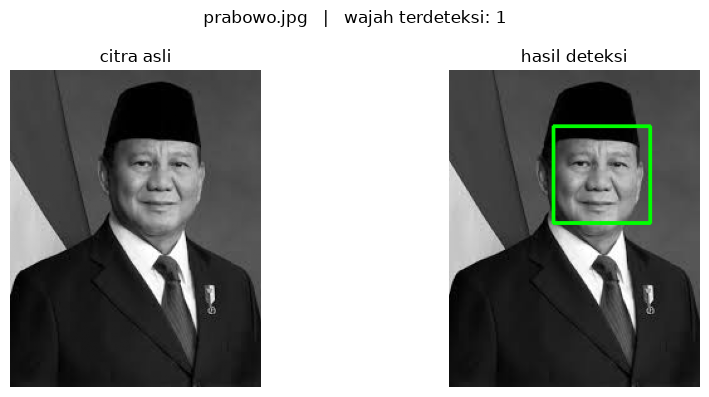

In [8]:
cascade_wajah = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_frontalface_alt.xml'))

daftar = ['jokowi.jpg', 'kartini.jpg', 'kucing.jpg', 'mask.png',
          'mjordan.jpg', 'solvayconf.jpg', 'prabowo.jpg']
for nama in daftar:
    citra = cv.imread(os.path.join(FD, nama), 0)
    roi_wajah = cascade_wajah.detectMultiScale(citra)
    hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)
    for (x, y, w, h) in roi_wajah:
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)

    n = 0 if len(roi_wajah) == 0 else len(roi_wajah)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(f'{nama}   |   wajah terdeteksi: {n}', fontsize=12)
    ax[0].imshow(citra, cmap='gray'); ax[0].set_title('citra asli');     ax[0].axis('off')
    ax[1].imshow(hasil, cmap='gray'); ax[1].set_title('hasil deteksi');  ax[1].axis('off')
    plt.tight_layout(); plt.show()
    cv.imwrite(os.path.join(OUTPUT, f'soal8_{nama}'), hasil)

### 8. Cat Face Detection

Wajah kucing terdeteksi : 1


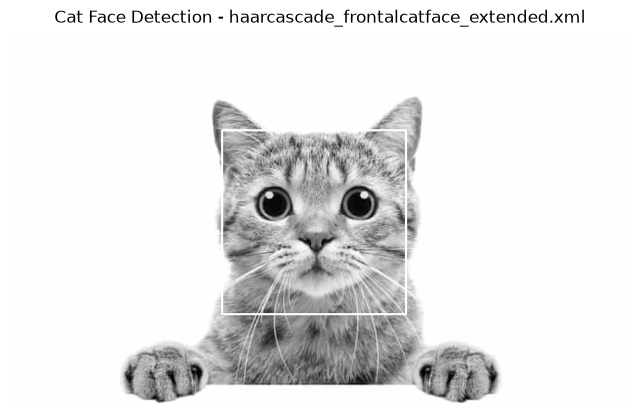

True

In [9]:
cascade_kucing = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_frontalcatface_extended.xml'))
citra = cv.imread(os.path.join(FD, 'kucing.jpg'), 0)
roi_kucing = cascade_kucing.detectMultiScale(citra, scaleFactor=1.1, minNeighbors=5, minSize=(75, 75))

hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)
for (x, y, w, h) in roi_kucing:
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 255, 255), 2)
print('Wajah kucing terdeteksi :', len(roi_kucing))

plt.figure(figsize=(8, 5))
plt.imshow(hasil, cmap='gray')
plt.title('Cat Face Detection - haarcascade_frontalcatface_extended.xml')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal9_kucing.jpg'), hasil)

### 9. Eyes Detection pada Wajah Pak Prabowo

Wajah terdeteksi : 1 | Mata terdeteksi : 2


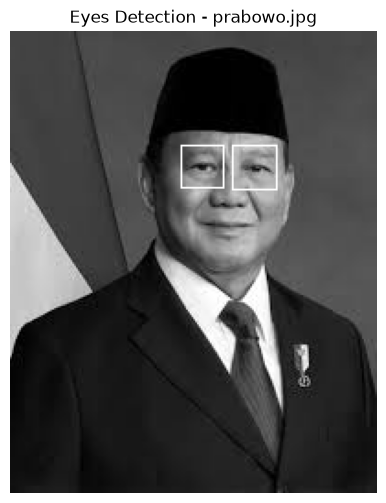

True

In [10]:
cascade_wajah = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_frontalface_alt.xml'))
cascade_mata  = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_eye.xml'))

citra = cv.imread(os.path.join(FD, 'prabowo.jpg'), 0)
hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)

roi_wajah = cascade_wajah.detectMultiScale(citra)
jumlah_mata = 0
for (x, y, w, h) in roi_wajah:
    roi = citra[y:y + h, x:x + w]
    mata = cascade_mata.detectMultiScale(roi, scaleFactor=1.05, minNeighbors=3)
    for (ex, ey, ew, eh) in mata:
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), (255, 255, 255), 1)
        jumlah_mata += 1
print('Wajah terdeteksi :', len(roi_wajah), '| Mata terdeteksi :', jumlah_mata)

plt.figure(figsize=(5, 6))
plt.imshow(hasil, cmap='gray')
plt.title('Eyes Detection - prabowo.jpg')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal10_eyes_prabowo.jpg'), hasil)

### 10. Deteksi Senyuman (Smile Detection)

solvayconf.jpg -> wajah : 30 | senyum : 2


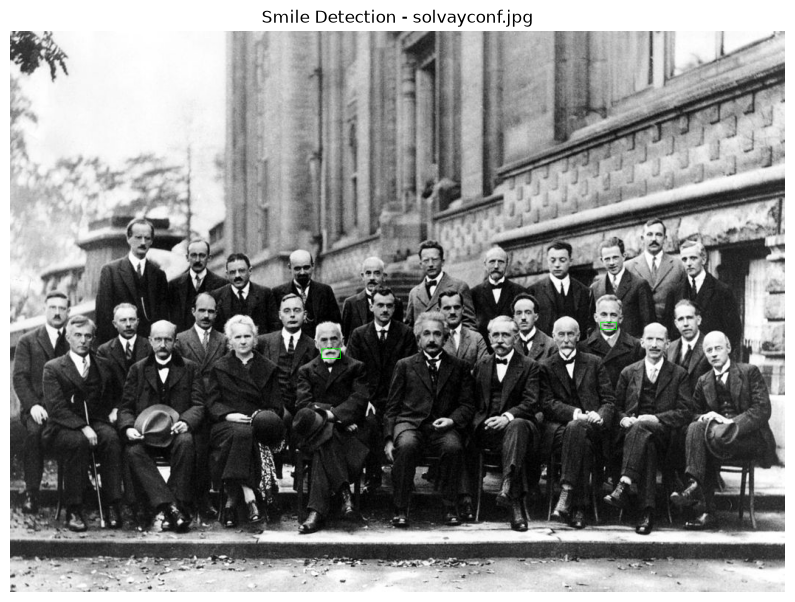

mjordan.jpg    -> wajah : 1 | senyum : 2


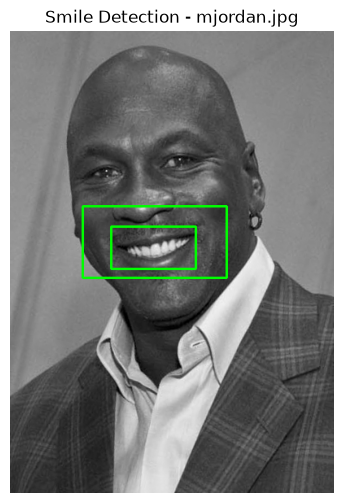

True

In [11]:
cascade_wajah  = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_frontalface_alt.xml'))
cascade_senyum = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_smile.xml'))

# ---------- a. gambar kelompok solvayconf.jpg ----------
citra  = cv.imread(os.path.join(FD, 'solvayconf.jpg'), 0)
citra3 = cv.resize(citra, None, fx=3, fy=3, interpolation=cv.INTER_CUBIC)
hasil  = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)

wajah = cascade_wajah.detectMultiScale(citra3, 1.1, 5)
jumlah_senyum = 0
for (x, y, w, h) in wajah:
    roi = citra3[y:y + h, x:x + w]
    senyum = cascade_senyum.detectMultiScale(roi, scaleFactor=1.3, minNeighbors=7, minSize=(25, 25))
    for (sx, sy, sw, sh) in senyum:
        p1 = (int((x + sx) / 3), int((y + sy) / 3))
        p2 = (int((x + sx + sw) / 3), int((y + sy + sh) / 3))
        cv.rectangle(hasil, p1, p2, (0, 255, 0), 1)
        jumlah_senyum += 1
print('solvayconf.jpg -> wajah :', len(wajah), '| senyum :', jumlah_senyum)
plt.figure(figsize=(10, 8))
plt.imshow(hasil, cmap='gray')
plt.title('Smile Detection - solvayconf.jpg')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal11a_smile_solvay.jpg'), hasil)

# ---------- b. mjordan.jpg ----------
citra = cv.imread(os.path.join(FD, 'mjordan.jpg'), 0)
hasil = cv.cvtColor(citra, cv.COLOR_GRAY2BGR)
wajah = cascade_wajah.detectMultiScale(citra)
jumlah_senyum = 0
for (x, y, w, h) in wajah:
    roi = citra[y:y + h, x:x + w]
    senyum = cascade_senyum.detectMultiScale(roi, scaleFactor=1.7, minNeighbors=11)
    for (sx, sy, sw, sh) in senyum:
        cv.rectangle(hasil, (x + sx, y + sy), (x + sx + sw, y + sy + sh), (0, 255, 0), 2)
        jumlah_senyum += 1
print('mjordan.jpg    -> wajah :', len(wajah), '| senyum :', jumlah_senyum)
plt.figure(figsize=(5, 6))
plt.imshow(hasil, cmap='gray')
plt.title('Smile Detection - mjordan.jpg')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal11b_smile_mjordan.jpg'), hasil)

### 11. Face Tracking dengan Google Colab (Live Camera)

In [ ]:
# ================================================================
# Jalankan sel ini pada GOOGLE COLAB (butuh akses webcam browser)
# ================================================================
import cv2 as cv
import numpy as np
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def video_stream():
    js = Javascript('''
    var video, div = null;
    async function createStream() {
      div = document.createElement('div');
      video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
    }
    async function captureFrame() {
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      return canvas.toDataURL('image/jpeg', 0.8);
    }
    async function stopStream() {
      video.srcObject.getVideoTracks()[0].stop();
      div.remove();
    }
    ''')
    display(js)
    eval_js('createStream()')

def ambil_frame():
    data = eval_js('captureFrame()')
    return cv.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), cv.IMREAD_COLOR)

cascade_wajah = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_alt.xml')

video_stream()                       # mulai stream kamera
for i in range(100):                 # lakukan face tracking pada 100 frame
    frame = ambil_frame()
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    wajah = cascade_wajah.detectMultiScale(gray, 1.1, 4)
    for (x, y, w, h) in wajah:
        cv.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
    _, buf = cv.imencode('.jpg', frame)
    display(IPython.display.Image(data=buf.tobytes()))
eval_js('stopStream()')              # hentikan kamera

### 12. Blurring pada Wajah yang Terdeteksi

Wajah terdeteksi : 1


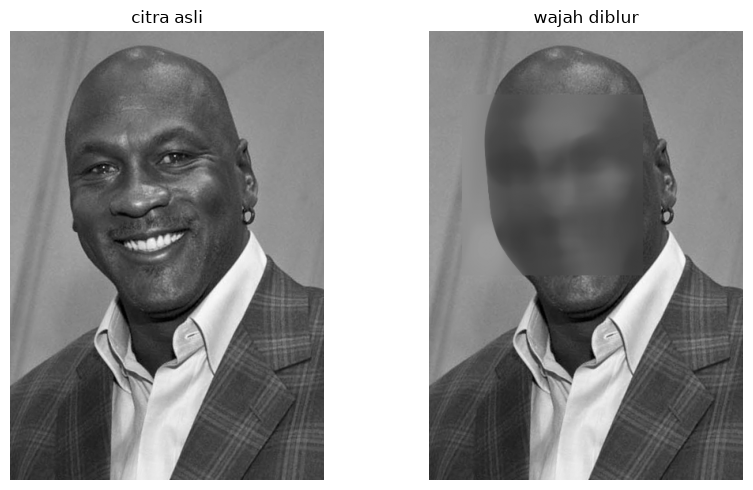

True

In [13]:
cascade_wajah = cv.CascadeClassifier(os.path.join(HAAR, 'haarcascade_frontalface_alt.xml'))

citra = cv.imread(os.path.join(FD, 'mjordan.jpg'), 0)
wajah = cascade_wajah.detectMultiScale(citra)
print('Wajah terdeteksi :', len(wajah))

blur_penuh = cv.medianBlur(citra, 51)          # blur diterapkan ke seluruh citra
hasil = citra.copy()
for (x, y, w, h) in wajah:
    hasil[y:y + h, x:x + w] = blur_penuh[y:y + h, x:x + w]   # ambil area wajah saja

fig, ax = plt.subplots(1, 2, figsize=(9, 5))
ax[0].imshow(citra, cmap='gray'); ax[0].set_title('citra asli');    ax[0].axis('off')
ax[1].imshow(hasil, cmap='gray'); ax[1].set_title('wajah diblur');  ax[1].axis('off')
plt.tight_layout(); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal13_blur_wajah.jpg'), hasil)

### 13. Mengolah Gambar KTM

**a. Tampilkan KTM**

Ukuran KTM : (1727, 2722, 3)


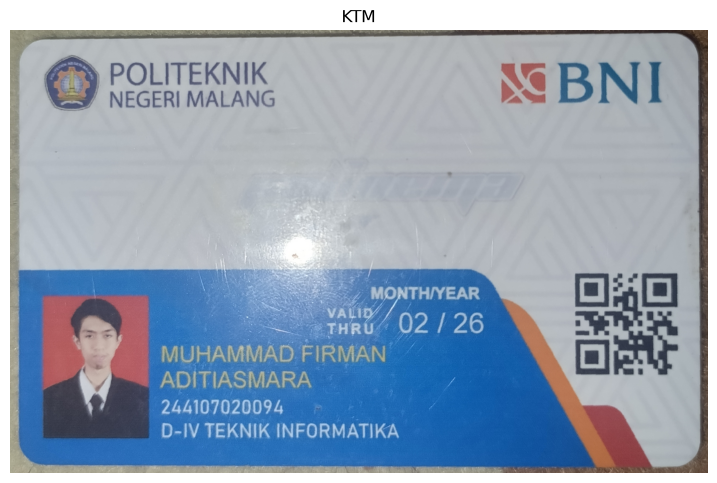

In [14]:
file_ktm = os.path.join(PATH, 'KTM.jpg')   # berkas KTM milik sendiri
ktm = cv.imread(file_ktm)
print('Ukuran KTM :', ktm.shape)

plt.figure(figsize=(9, 6))
plt.imshow(cv.cvtColor(ktm, cv.COLOR_BGR2RGB))
plt.title('KTM')
plt.axis('off'); plt.show()

**b. Tampilkan Foto KTM**

Wajah terdeteksi : 1


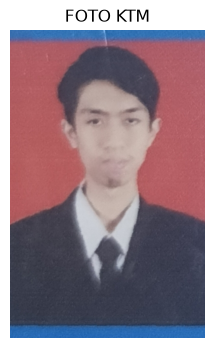

True

In [15]:
gray  = cv.cvtColor(ktm, cv.COLOR_BGR2GRAY)
wajah = cascade_wajah.detectMultiScale(gray)
print('Wajah terdeteksi :', len(wajah))

x, y, w, h = max(wajah, key=lambda r: r[2] * r[3])     # ambil wajah terbesar
# perluas area crop agar foto terlihat utuh
x1, y1 = max(0, x - int(0.5 * w)), max(0, y - int(0.5 * h))
x2, y2 = min(ktm.shape[1], x + int(1.4 * w)), min(ktm.shape[0], y + int(2.5 * h))
foto_ktm = ktm[y1:y2, x1:x2]

plt.figure(figsize=(4, 4))
plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal14b_foto_ktm.jpg'), foto_ktm)

**c. Deteksi Objek KTM pada gambar yang berisi KTM bersama barang lain dengan Konsep Feature Matching**

Keypoint template KTM : 500
Keypoint komposit     : 500
Jumlah match          : 323


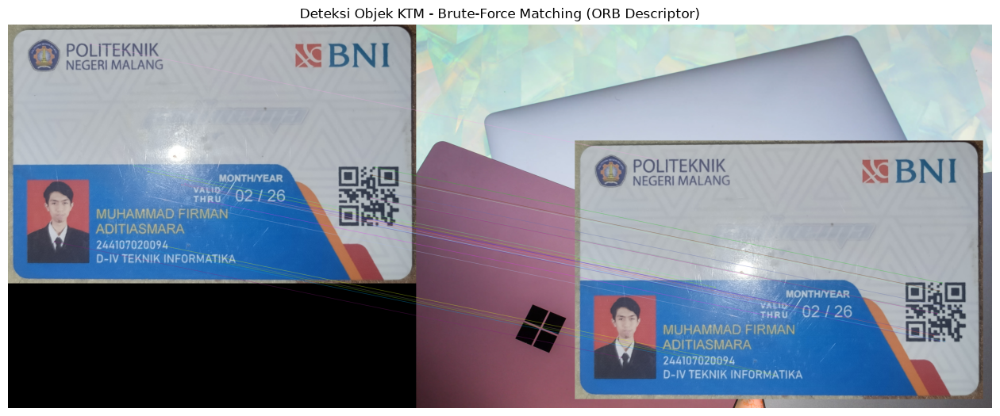

True

In [16]:
# --- simulasi komposit: KTM bersama barang lain (laptop) ---
latar = cv.imread(os.path.join(IMG, 'laptop.jpg'))
kh, kw = ktm.shape[:2]
x0 = latar.shape[1] - kw - 60      # posisi kanan-bawah agar tidak keluar batas
y0 = latar.shape[0] - kh - 60
komposit = latar.copy()
komposit[y0:y0 + kh, x0:x0 + kw] = ktm
cv.imwrite(os.path.join(OUTPUT, 'soal14c_komposit.jpg'), komposit)

# --- Brute-Force Matching dengan ORB Descriptor ---
orb = cv.ORB_create()
kp1, des1 = orb.detectAndCompute(ktm, None)
kp2, des2 = orb.detectAndCompute(komposit, None)
print('Keypoint template KTM :', len(kp1))
print('Keypoint komposit     :', len(kp2))

bf = cv.BFMatcher(cv.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(des1, des2), key=lambda x: x.distance)
print('Jumlah match          :', len(matches))

hasil_match = cv.drawMatches(ktm, kp1, komposit, kp2, matches[:25], None, flags=2)
plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(hasil_match, cv.COLOR_BGR2RGB))
plt.title('Deteksi Objek KTM - Brute-Force Matching (ORB Descriptor)')
plt.axis('off'); plt.show()
cv.imwrite(os.path.join(OUTPUT, 'soal14c_match.jpg'), hasil_match)

## D3. Tugas Pengayaan: Pengenalan Karakter KTM dengan CNN

In [ ]:
# =================================================================
# 1. PERSIAPAN DATA TRAINING (dataset/training/<karakter>/<img>.jpg)
# =================================================================
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"      # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))             # daftar nama kelas
training_data = []
for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

In [ ]:
# =================================================================
# 2. TRAINING DATA (arsitektur CNN)
# =================================================================
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]        # diambil dari data, tidak ditulis tetap

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training  :", riwayat.history['accuracy'][-1])
print("akurasi validasi  :", riwayat.history['val_accuracy'][-1])

In [ ]:
# =================================================================
# 3. TESTING DATA (dataset/testing/<plat>/<karakter>.jpg)
# =================================================================
import os
import cv2
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))   # urutan kelas saat training

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv2.imread(os.path.join(folder, char_img),
                               cv2.IMREAD_GRAYSCALE)
        new_array = cv2.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))